#1. Load the dataset

I’m using the supplied Telco dataset to predict whether a customer churns. I’ll prepare the data, train a baseline neural network and compare it with a tuned version.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#2. Inspect the data

In [3]:
print("Shape:", df.shape)
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn counts:")
print(df["Churn"].value_counts())

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

The dataset contains 7,043 rows and 21 columns, there are no fully duplicated rows. The initial missing-value check does not identify the blank TotalCharges entries because they are stored as text rather than actual missing values.

#3. Clean TotalCharges
This uses a cleaning function and .apply(), as I learnt in Lab 3.

In [4]:
def clean_total_charges(value):
    if isinstance(value, str):
        value = value.strip()

        if value == "":
            return np.nan

    return float(value)

df_clean = df.copy()

df_clean["TotalCharges"] = df_clean["TotalCharges"].apply(
    clean_total_charges
)

print("Missing TotalCharges:", df_clean["TotalCharges"].isnull().sum())

df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()

print("Cleaned shape:", df_clean.shape)
print("TotalCharges type:", df_clean["TotalCharges"].dtype)

Missing TotalCharges: 11
Cleaned shape: (7032, 21)
TotalCharges type: float64


I converted TotalCharges into numbers and treated blank strings as missing values. I removed the 11 affected rows because they make up a small part of the dataset, leaving 7,032 records. This avoids filling in a charge amount that was not recorded.

#4. Exploring churn

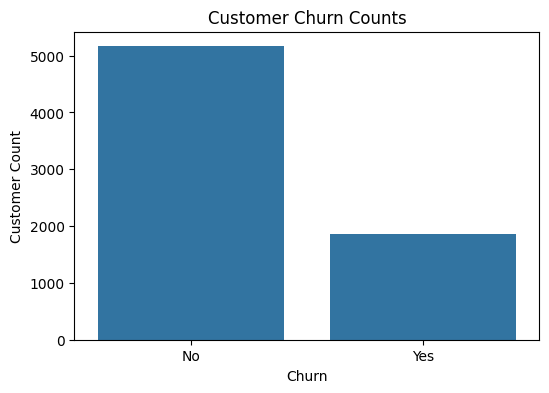

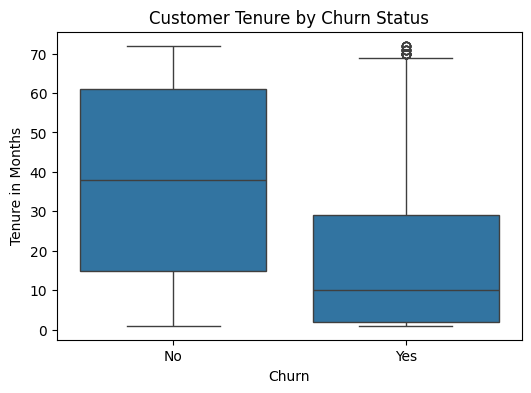

Churn
No     5163
Yes    1869
Name: count, dtype: int64
          tenure             
            mean median count
Churn                        
No     37.650010   38.0  5163
Yes    17.979133   10.0  1869


In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Churn", data=df_clean)
plt.title("Customer Churn Counts")
plt.xlabel("Churn")
plt.ylabel("Customer Count")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(x="Churn", y="tenure", data=df_clean)
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure in Months")
plt.show()

print(df_clean["Churn"].value_counts())

print(
    df_clean.groupby("Churn").agg({
        "tenure": ["mean", "median", "count"]
    })
)

More customers stayed than churned, so the classes are imbalanced. I also compared tenure between the two groups to check whether customers who left tended to have shorter relationships with the company. I’ll use precision, recall and F1 alongside accuracy so the larger non-churn group does not hide poor churn detection.

#5. Separate inputs and target

I’m excluding customerID because it identifies the customer rather than describing their account. I’m mapping churn to zero and one, with one representing a customer who churned.

In [6]:
input_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges",
    "TotalCharges"
]

X_raw = df_clean[input_columns].copy()

y = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

#6. Encode categories

In [7]:
categorical_columns = list(
    X_raw.select_dtypes(include="object").columns
)

X = pd.get_dummies(
    X_raw,
    columns=categorical_columns,
    drop_first=True
)

feature_names = X.columns.tolist()

print("Prepared input shape:", X.shape)
print(feature_names)

Prepared input shape: (7032, 30)
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


I used one-hot encoding for the text columns. For example, payment methods do not have a meaningful numerical order, so giving them labels such as one, two and three could be misleading. SeniorCitizen is already a zero-or-one indicator, so I kept it as it was.

#7. Create training, validation and test sets
This will repeat the train_test_split() that I learnt in Lab 6 twice.

In [8]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 4218
Validation rows: 1407
Test rows: 1407


I reserved 20% of the data for testing and split the remaining data into training and validation sets. This gives approximately 60% training, 20% validation and 20% testing. I’ll compare the models using validation F1 before evaluating the selected model on the test set.

#8. Scaling the numerical measurements

In [9]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

X_val_scaled[numeric_columns] = scaler.transform(
    X_val[numeric_columns]
)

X_test_scaled[numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

X_train_scaled = X_train_scaled.astype("float32")
X_val_scaled = X_val_scaled.astype("float32")
X_test_scaled = X_test_scaled.astype("float32")

I fitted the scaler using only the training data, then applied it to validation and test data. I scaled tenure and the two charge columns while leaving the binary indicators unchanged. I converted the prepared inputs to float32, using the conversion I learnt in Lab 13.

#9. Building the baseline

In [10]:
baseline_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline_model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=1
)

Epoch 1/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7003 - loss: 0.5464 - val_accuracy: 0.7882 - val_loss: 0.4541
Epoch 2/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7940 - loss: 0.4336 - val_accuracy: 0.7946 - val_loss: 0.4270
Epoch 3/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8018 - loss: 0.4207 - val_accuracy: 0.8031 - val_loss: 0.4207
Epoch 4/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8046 - loss: 0.4165 - val_accuracy: 0.8038 - val_loss: 0.4188
Epoch 5/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8054 - loss: 0.4127 - val_accuracy: 0.8060 - val_loss: 0.4183
Epoch 6/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8084 - loss: 0.4100 - val_accuracy: 0.8081 - val_loss: 0.4174
Epoch 7/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8068 - loss: 0.4087 - val_accuracy: 0.8031 - val_loss: 0.4177
Epoch 8/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8115 - loss: 0.4057 - val_accuracy: 0.

The baseline has two hidden Dense layers with 32 and 16 neurons. I used a sigmoid output and binary cross-entropy because the target has two classes. This gives me a starting point before adding tuning techniques.

#10. Plot baseline loss

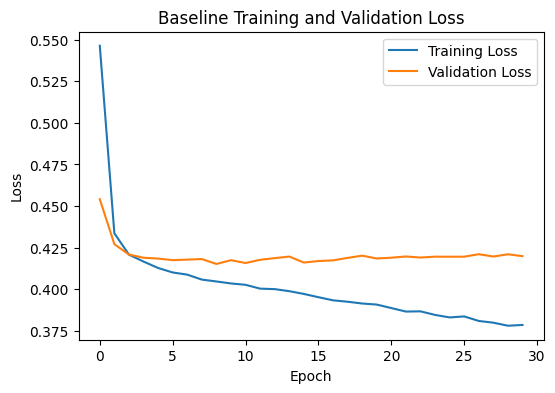

In [11]:
plt.figure(figsize=(6, 4))
plt.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Training and Validation Loss")
plt.legend()
plt.show()

Training and validation loss both drop during the first few epochs. After that, validation loss stays around 0.42 while training loss continues falling to about 0.38. This widening gap suggests some overfitting, although validation loss mostly levels off rather than rising sharply.

#11. Build the tuned model

In [12]:
tuned_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),
    layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dense(1, activation="sigmoid")
])

tuned_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

tuned_history = tuned_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6
        )
    ],
    verbose=1
)

print("Epochs run:", len(tuned_history.history["loss"]))

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7477 - loss: 0.5533 - val_accuracy: 0.7825 - val_loss: 0.4892 - learning_rate: 0.0010
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7783 - loss: 0.4961 - val_accuracy: 0.7946 - val_loss: 0.4711 - learning_rate: 0.0010
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7985 - loss: 0.4695 - val_accuracy: 0.7925 - val_loss: 0.4605 - learning_rate: 0.0010
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7935 - loss: 0.4613 - val_accuracy: 0.7982 - val_loss: 0.4540 - learning_rate: 0.0010
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7961 - loss: 0.4581 - val_accuracy: 0.8017 - val_loss: 0.4512 - learning_rate: 0.0010
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7980 - loss: 0.4540 - val_accuracy: 0.7989 - val_loss: 0.4492 - learning_rate: 0.0010
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7992 - loss: 0.

I kept the hidden-layer sizes the same and added tuning techniques from Lab 15. Dropout and L2 discourage over-reliance on particular activations or large weights. Early Stopping restores the weights from the best validation-loss epoch, while the scheduler reduces the learning rate when improvement slows down.

#12. Plot tuned loss

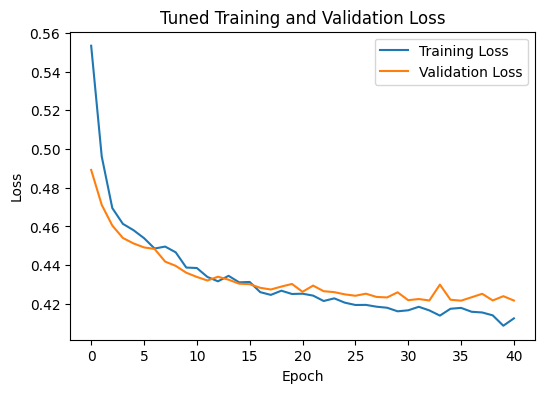

In [13]:
plt.figure(figsize=(6, 4))
plt.plot(
    tuned_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    tuned_history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Tuned Training and Validation Loss")
plt.legend()
plt.show()

Training and validation loss generally decrease together and stay close, so there is no clear sign of overfitting during this run. Validation loss levels off around 0.42 towards the end. L2 adds a penalty to the loss, so I cannot directly compare these loss values with the baseline’s unpenalised loss.

#13. Select using validation F1

In [14]:
baseline_val_probs = baseline_model.predict(
    X_val_scaled, verbose=0
)
baseline_val_labels = baseline_val_probs[:, 0] >= 0.5

tuned_val_probs = tuned_model.predict(
    X_val_scaled, verbose=0
)
tuned_val_labels = tuned_val_probs[:, 0] >= 0.5

baseline_val_f1 = f1_score(y_val, baseline_val_labels)
tuned_val_f1 = f1_score(y_val, tuned_val_labels)

print("Baseline validation F1:", baseline_val_f1)
print("Tuned validation F1:", tuned_val_f1)

if tuned_val_f1 > baseline_val_f1:
    best_model = tuned_model
    selected_name = "Tuned"
else:
    best_model = baseline_model
    selected_name = "Baseline"

print("Selected model:", selected_name)

Baseline validation F1: 0.6002844950213371
Tuned validation F1: 0.6005830903790087
Selected model: Tuned


I selected the model using validation F1 because I want to consider both precision and recall for churn. If the tuned model scores lower, I’ll keep the baseline rather than claim that tuning improved it. The decision is made before comparing test results.

#14. Report the before-and-after test accuracies

In [15]:
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

tuned_test_loss, tuned_test_accuracy = tuned_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

comparison = pd.DataFrame({
    "Model": ["Baseline", "Tuned"],
    "Validation F1": [baseline_val_f1, tuned_val_f1],
    "Test Accuracy": [
        baseline_test_accuracy,
        tuned_test_accuracy
    ]
})

print(comparison)

      Model  Validation F1  Test Accuracy
0  Baseline       0.600284       0.789623
1     Tuned       0.600583       0.786070


The baseline test accuracy was 78.96%, compared with 78.61% for the tuned model. I selected the tuned model because its validation F1 was slightly higher (0.6006 compared with 0.6003). The tuning techniques did not improve test accuracy in this run.

#15. Evaluate the selected model

Selected model: Tuned
Accuracy: 0.7860696517412935
Precision: 0.6367041198501873
Recall: 0.45454545454545453
F1: 0.5304212168486739

Confusion matrix:
[[936  97]
 [204 170]]


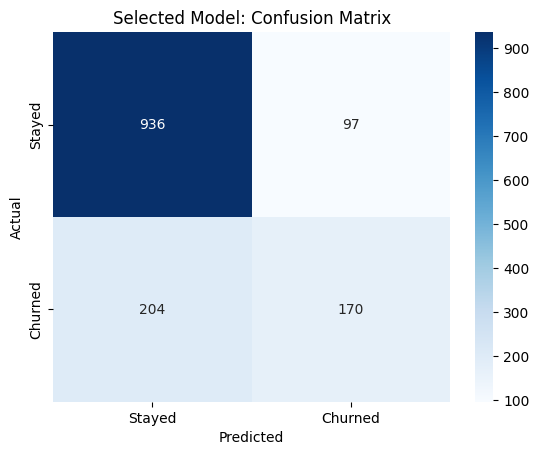

In [16]:
best_probabilities = best_model.predict(
    X_test_scaled, verbose=0
)

best_labels = best_probabilities[:, 0] >= 0.5

print("Selected model:", selected_name)
print("Accuracy:", accuracy_score(y_test, best_labels))
print("Precision:", precision_score(y_test, best_labels))
print("Recall:", recall_score(y_test, best_labels))
print("F1:", f1_score(y_test, best_labels))

cm = confusion_matrix(y_test, best_labels)

print("\nConfusion matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Selected Model: Confusion Matrix")
plt.show()

Accuracy alone could be misleading because around 73% of customers did not churn, so predicting everyone stayed would already achieve around 73% accuracy. My model achieved 78.61% accuracy, but it only identified 170 of the 374 customers who churned (45.45% recall), missing the other 204.

#16. Saving the model and preprocessing information

In [17]:
best_model.save("Assignment3_Maryam_Chaudhry.keras")

In [18]:
import joblib

preprocessing = {
    "scaler": scaler,
    "feature_names": feature_names,
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns
}

joblib.dump(
    preprocessing,
    "Assignment3_Maryam_Chaudhry_preprocessing.joblib"
)

['Assignment3_Maryam_Chaudhry_preprocessing.joblib']

I saved the selected network as a Keras file. I also saved the fitted scaler and column information so new customer data can be prepared in the same way without retraining.

#17. Writing the loading and prediction function

In [19]:
def predict_customer_churn(customer):
    loaded_model = keras.models.load_model(
        "Assignment3_Maryam_Chaudhry.keras"
    )

    preparation = joblib.load(
        "Assignment3_Maryam_Chaudhry_preprocessing.joblib"
    )

    customer_df = pd.DataFrame([customer])

    customer_encoded = pd.get_dummies(
        customer_df,
        columns=preparation["categorical_columns"],
        drop_first=False
    )

    for column in preparation["feature_names"]:
        if column not in customer_encoded.columns:
            customer_encoded[column] = 0

    customer_encoded = customer_encoded[
        preparation["feature_names"]
    ].copy()

    customer_encoded[preparation["numeric_columns"]] = (
        preparation["scaler"].transform(
            customer_encoded[preparation["numeric_columns"]]
        )
    )

    customer_encoded = customer_encoded.astype("float32")

    probability = loaded_model.predict(
        customer_encoded,
        verbose=0
    )[0][0]

    return probability

#18. Testing one hypothetical customer

In [20]:
new_customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 12,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "Yes",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "Yes",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 60.0,
    "TotalCharges": 720.0
}

churn_probability = predict_customer_churn(new_customer)

print("Predicted churn score:", churn_probability)

if churn_probability >= 0.5:
    print("Prediction: Churn")
else:
    print("Prediction: Stay")

Predicted churn score: 0.26258528
Prediction: Stay


I tested the saved model with one hypothetical customer using the same input columns as training. The function loads the network and preprocessing information, prepares the customer and returns a churn score. This checks the prediction workflow; it does not establish whether this individual prediction is correct.

#CNN vs RNN
I would use a CNN for image data because its filters learn local patterns such as edges and shapes, as in the clothing classification lab. A Dense network can work with images, but it does not build in the same local structure and shared filters. I would use an RNN for ordered sequences, such as predicting sentiment from a movie review, because earlier words can affect the meaning of later ones. For this customer dataset, a Dense network is a suitable starting point because each customer is represented by a row of account features.